# Bitacoras onomásticas SEMEFO 1968-1982
# Análisis demográfico

In [1]:
import pandas as pd
from numpy import nan

import matplotlib.pyplot as plt
import seaborn as sns

def summary_top_series(s, n_values=5, sep=', ', **kwargs):
    s = s.value_counts(**kwargs).head(n_values)
    s = s.to_dict()
    s = sep.join([f"{k} ({v})" for k,v in s.items()])
    return s

In [2]:
df = pd.read_pickle('data_clean/SEMEFO_BO_all.pkl')
df['Bitacora_ingresos'] = df['Bitacora_ingresos'].apply(lambda s: s.replace('semefo_df_bo_',''))
df

,ID,Numero_progresivo_transcrito,Nombre_completo_transcrito,Primer_apellido,Segundo_apellido,Nombres_propios,Fecha_transcrito,Fecha_estandar,Fecha_añomes,Fecha_diasemana,...,Procedencia_acta,Diagnostico_transcrito,Diagnostico_estandar,Diagnostico_extendido,Tipo_restos,Conocido_desconocido,Bitacora_ingresos,Pagina_PDF,Foja_transcrito,Observaciones
0,BO_1971_01274,NaN,diaz luna alejandro,diaz,luna,alejandro,10/5/1971,1971-05-10,1971 Mayo,Lunes,...,NaN,S-D,S-D,S-D,Cadáver,conocido,1971,39,30 reverso,NaN
1,BO_1974_00051,51.0,alfora herrera antonio,alfora,herrera,antonio,27/2/1974,1974-02-27,1974 Febrero,Miércoles,...,11A/181,Quemaduras,QUEM,quemaduras,Cadáver,conocido,1974,4,1 reverso,NaN
2,BO_1975_04776,144.0,sandoval ortiz castulo,sandoval,ortiz,castulo,28/5/1975,1975-05-28,1975 Mayo,Miércoles,...,C-1/863,FCPN,FCPN,falta cuidado post natales,Cadáver,conocido,1975,147,86,NaN
3,BO_1974_00247,247.0,aldo mucino maribel,aldo,mucino,maribel,11/10/1974,1974-10-11,1974 Octubre,Viernes,...,25A/380,AOVA,AOVA,asfixia por obstruccion de vias aereas,Cadáver,conocido,1974,10,4 reverso,NaN
4,BO_1974_00081,81.0,alcantar valero emma,alcantar,valero,emma,3/4/1974,1974-04-03,1974 Abril,Miércoles,...,12A/406,TCT,TCT,traumatismo craneo torax,Cadáver,conocido,1974,5,2,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96855,BO_1982_07489,NaN,placenta,S-D,S-D,S-D,5/6/1982,1982-06-05,1982 Junio,Sábado,...,15A/960,S-D,S-D,S-D,Miembros,desconocido,1982,251,156,NaN
96856,BO_1982_07490,NaN,5 dedos del pie derecho de desconocido,S-D,S-D,S-D,5/6/1982,1982-06-05,1982 Junio,Sábado,...,32A/950,S-D,S-D,S-D,Miembros,desconocido,1982,251,156,NaN
96857,BO_1982_07491,NaN,dedo de desconocido,S-D,S-D,S-D,19/11/1982,1982-11-19,1982 Noviembre,Viernes,...,32A/2005,S-D,S-D,S-D,Miembros,desconocido,1982,251,156,NaN
96858,BO_1982_07492,NaN,4 dedos de desconocido,S-D,S-D,S-D,28/11/1982,1982-11-28,1982 Noviembre,Domingo,...,27A/959,S-D,S-D,S-D,Miembros,desconocido,1982,251,156,NaN


## Missing

In [4]:
pd.DataFrame( df['Bitacora_ingresos'].value_counts().sort_index())

,count
Bitacora_ingresos,
1968,4719
1969,5052
1970,5303
1971,5524
1972,5770
1973,6471
1974,5731
1975,6861
1976,6907


In [5]:
col_trans = [col for col in df.columns if 'transcrito' in col]
col_trans

data = df[col_trans]
data['Año'] = df['Bitacora_ingresos'].replace({'semefo_df_':''}, regex=True)
data = data.replace({'S-D':nan, 's-d':nan})

/tmp/ipykernel_19103/2440187126.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data['Año'] = df['Bitacora_ingresos'].replace({'semefo_df_':''}, regex=True)


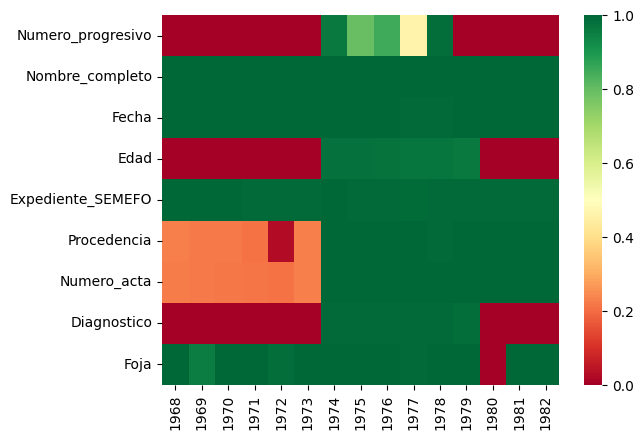

In [6]:
data_miss = data.groupby('Año').agg({col:lambda s: s.notna().sum() / len(s) for col in col_trans })
data_miss.index = [i.replace('semefo_df_bo_','') for i in data_miss.index]
data_miss.columns = [i.replace('_transcrito','') for i in data_miss.columns]
#display( data_miss )
sns.heatmap(data_miss.transpose(), cmap='RdYlGn')
plt.show()

## Tipo de restos

,Frecuencia,Porcentaje
Tipo_restos,,
Cadáver,91253,94.211233
Feto,2844,2.936197
Miembros,2064,2.130911
Recién nacido,633,0.653521
Restos óseos,48,0.049556
S-D,18,0.018584


<Axes: >

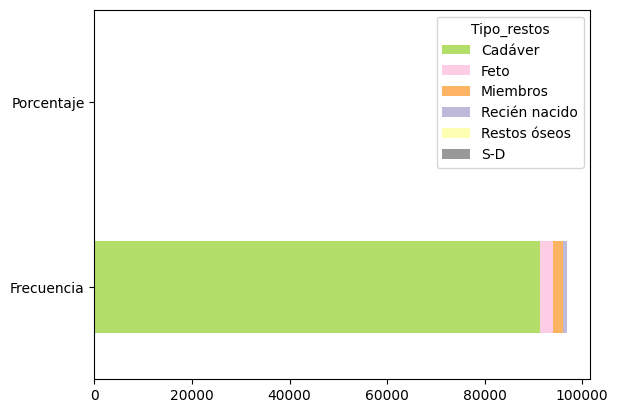

In [26]:
data = df['Tipo_restos'].value_counts()
data = pd.DataFrame(data)
data['mean'] = df['Tipo_restos'].value_counts(normalize=True)*100
data.columns = ['Frecuencia','Porcentaje']
display(data)
data.transpose().plot.barh(stacked=True, color=colors)

In [9]:
data = pd.pivot_table(df, index='Tipo_restos', columns=['Conocido_desconocido','Sexo'], aggfunc="size")
data

Conocido_desconocido conocido                desconocido                
Sexo                 Femenino Masculino  S-D    Femenino Masculino   S-D
Tipo_restos                                                             
Cadáver                 17923     58336  496        1580     12845    73
Recién nacido               8        23    0         243       356     3
Feto                        6         9   16         456       653  1704
Miembros                  361      1405   29          23       106   140
Restos óseos                0         0    0           1         7    40
S-D                         0         0    0           0         0    18

In [36]:
data = pd.pivot_table(df, index='Tipo_restos', columns='Conocido_desconocido', aggfunc="size")
data.divide(data.sum(axis=1), axis=0)

Conocido_desconocido,conocido,desconocido
Tipo_restos,,
Cadáver,0.841123,0.158877
Recién nacido,0.048973,0.951027
Feto,0.010900,0.989100
Miembros,0.869671,0.130329
Restos óseos,0.000000,1.000000
S-D,0.000000,1.000000


In [35]:
data = pd.pivot_table(df, index='Tipo_restos', columns='Sexo', aggfunc="size")
data.divide(data.sum(axis=1), axis=0)

Sexo,Femenino,Masculino,S-D
Tipo_restos,,,
Cadáver,0.213724,0.780040,0.006235
Recién nacido,0.396524,0.598736,0.004739
Feto,0.162447,0.232771,0.604782
Miembros,0.186047,0.732074,0.081880
Restos óseos,0.020833,0.145833,0.833333
S-D,0.000000,0.000000,1.000000


In [10]:
data = pd.pivot_table(df, index='Tipo_restos', columns='Bitacora_ingresos', aggfunc="size")
data / data.sum() * 100
#data.transpose().plot.barh(stacked=True, color=colors)

Bitacora_ingresos,1968,1969,1970,1971,1972,1973,1974,1975,1976,1977,1978,1979,1980,1981,1982
Tipo_restos,,,,,,,,,,,,,,,
Cadáver,93.134139,93.982581,93.286819,93.428675,93.431542,92.427755,92.392253,93.659816,94.614160,94.097125,94.534526,94.384131,95.970600,95.713724,96.249833
Recién nacido,0.720492,0.692795,0.999434,0.814627,0.953206,1.282646,0.907346,0.553855,0.115825,0.655875,0.615041,0.442300,0.380627,0.393236,0.627252
Feto,4.852723,3.661916,4.016594,4.091238,3.431542,4.265183,4.309894,3.293980,3.214131,2.525816,2.404249,1.997051,1.653760,1.415651,1.147738
Miembros,1.250265,1.583531,1.602866,1.593049,2.010399,1.746253,2.390508,2.419472,2.041407,2.693274,2.236511,3.176518,1.995012,2.477389,1.975177
Restos óseos,0.042382,0.079177,0.094286,0.054308,0.138648,0.262711,0.000000,0.072876,0.014478,0.027910,0.013978,0.000000,0.000000,0.000000,0.000000
S-D,0.000000,0.000000,0.000000,0.018103,0.034662,0.015454,0.000000,0.000000,0.000000,0.000000,0.195695,0.000000,0.000000,0.000000,0.000000


## Edad y sexo

In [11]:
colors = {'conocido':'#8dd3c7', 'desconocido':'#fb8072',
          'Femenino':'#bc80bd', 'Masculino':'#fb8072','S-D':'#999999',
          'Cadáver':'#b3de69', 'Feto':'#fccde5', 'Recién nacido':'#bebada', 'Miembros':'#fdb462', 'Restos óseos':'#ffffb3'}

<Axes: ylabel='Edad_rango'>

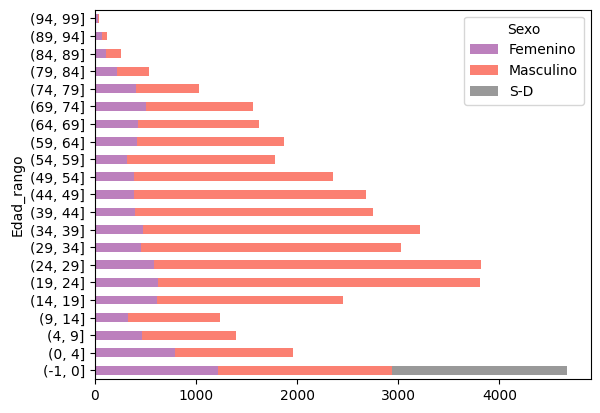

In [12]:
data = pd.pivot_table(df, index='Edad_rango', columns='Sexo', aggfunc="size")
data.plot.barh(stacked=True, color=colors)

<Axes: xlabel='Bitacora_ingresos'>

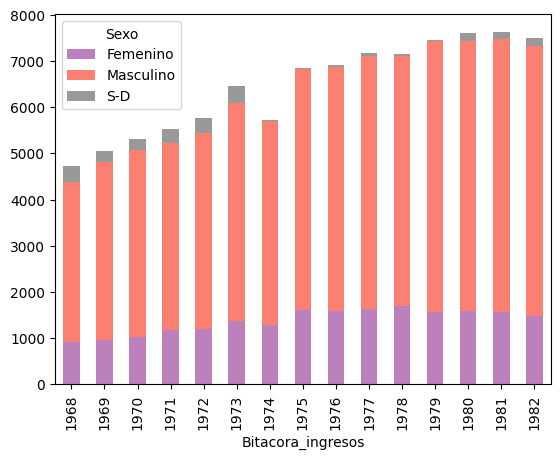

In [13]:
data = pd.pivot_table(df, index='Sexo', columns='Bitacora_ingresos', aggfunc="size")
data.transpose().plot.bar(stacked=True, color=colors)

## Procedencia y diagnóstico

## Fecha

<Axes: xlabel='Bitacora_ingresos'>

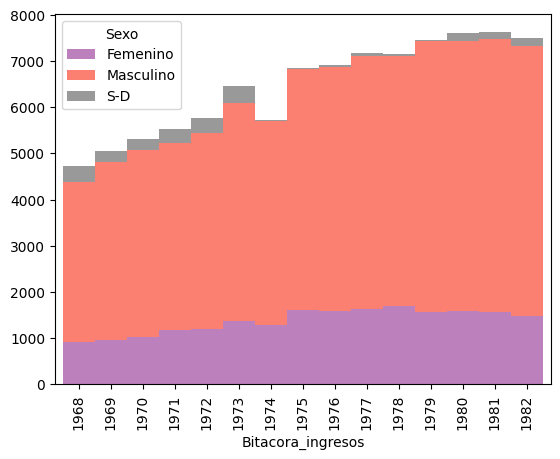

In [43]:
data = pd.pivot_table(df, index='Bitacora_ingresos', columns='Sexo', aggfunc="size")
data.plot.bar(stacked=True, width=1.0, color=colors)

<Axes: xlabel='Bitacora_ingresos'>

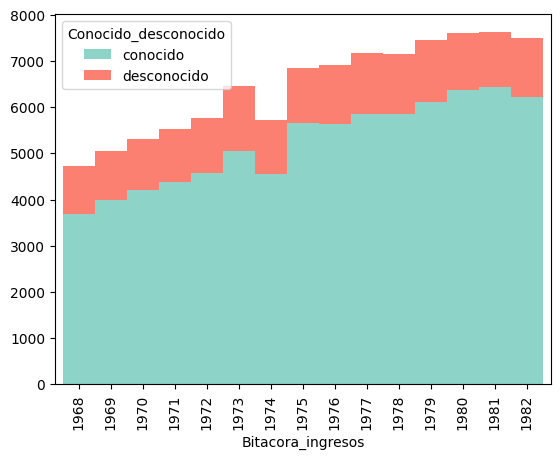

In [44]:
data = pd.pivot_table(df, index='Bitacora_ingresos', columns='Conocido_desconocido', aggfunc="size")
data.plot.bar(stacked=True, width=1.0, color=colors)

In [37]:
df.columns

Index(['ID', 'Numero_progresivo_transcrito', 'Nombre_completo_transcrito',
       'Primer_apellido', 'Segundo_apellido', 'Nombres_propios',
       'Fecha_transcrito', 'Fecha_estandar', 'Fecha_añomes', 'Fecha_diasemana',
       'Sexo', 'Edad_transcrito', 'Edad_estandar', 'Edad_rango',
       'Expediente_SEMEFO_transcrito', 'Procedencia_transcrito',
       'Procedencia_estandar', 'Procedencia_direccion', 'Procedencia_alcaldia',
       'Numero_acta_transcrito', 'Procedencia_acta', 'Diagnostico_transcrito',
       'Diagnostico_estandar', 'Diagnostico_extendido', 'Tipo_restos',
       'Conocido_desconocido', 'Bitacora_ingresos', 'Pagina_PDF',
       'Foja_transcrito', 'Observaciones'],
      dtype='object')